# CRISP-DM Project: Predicting & Reducing Customer Churn at a Telecom Provider

**Methodology:** CRISP-DM 1.0 (all 6 phases, every generic task and output)
**Dataset:** IBM/Kaggle *Telco Customer Churn* (7,043 customers, 21 columns) — https://www.kaggle.com/datasets/blastchar/telco-customer-churn
**Course:** SJSU Data Mining — Assignment: three methodologies (CRISP-DM · SEMMA · KDD), one dataset each.

Run in Google Colab: *Runtime → Run all*. The notebook downloads the data itself if `data/` is missing.

| Phase | Generic tasks covered |
|---|---|
| 1 Business Understanding | business objectives · situation assessment · data-mining goals · project plan |
| 2 Data Understanding | collect · describe · explore · verify quality |
| 3 Data Preparation | select · clean · construct · integrate · format |
| 4 Modeling | select technique · test design · build · assess |
| 5 Evaluation | evaluate results · review process · next steps |
| 6 Deployment | deployment plan · monitoring/maintenance · final report · project review |

> **Process note (critic loop):** each phase was reviewed by an LLM critic prompted as a world-renowned CRISP-DM authority. Findings and how I resolved them are in `critic_log/` and summarised in Phase 5.3. Every line of generated code was executed and checked by me; where the critic was right, the notebook changed.

In [1]:
import os, sys, json, warnings, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)

os.makedirs("data", exist_ok=True); os.makedirs("artifacts", exist_ok=True); os.makedirs("src", exist_ok=True); os.makedirs("deploy", exist_ok=True)
DATA = "data/WA_Fn-UseC_-Telco-Customer-Churn.csv"
MIRROR = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
if not os.path.exists(DATA):
    print("Downloading dataset mirror ...")
    urllib.request.urlretrieve(MIRROR, DATA)
print("Python", sys.version.split()[0], "| pandas", pd.__version__)

Python 3.14.7 | pandas 3.1.1


---
# Phase 1 — Business Understanding

## 1.1 Determine business objectives
**Background.** A telecom provider sells phone, internet and streaming bundles on monthly or term contracts. Acquiring a customer costs several times more than retaining one, and ~27% of customers in this sample churned in the last month.

**Business objective.** Reduce revenue lost to voluntary churn by targeting retention offers at customers who are likely to leave *and* worth keeping.

**Business success criteria (measurable).**
1. Retention campaign net value (saved revenue − offer cost − wasted offers) is higher than the two baselines: *no campaign* and *offer to everyone*.
2. The model identifies at least 2× more churners than random targeting in the top 20% of ranked customers (lift@20% ≥ 2).
3. Retention team can explain *why* a customer is flagged (interpretable drivers).

## 1.2 Assess the situation
| Item | Assessment |
|---|---|
| Resources | One analyst, a single CSV snapshot, free tooling (Python/Colab). No real-time CRM feed. |
| Requirements | Scores must be reproducible; predictions explainable to non-technical retention staff. |
| Assumptions | Snapshot is representative of the current base; `Churn` = left within the last month; `MonthlyCharges` is a proxy for monthly margin. |
| Constraints | No timestamps → no true temporal validation; no cost data → costs below are **assumptions** and are sensitivity-tested. |
| Risks | (a) Leakage — `TotalCharges ≈ tenure × MonthlyCharges`, tenure partly *results* from not churning; (b) class imbalance; (c) offering discounts to customers who would stay anyway; (d) fairness across gender / senior citizens. |
| Contingency | If the model is only marginally better than a one-rule baseline (contract type), ship the rule instead. |
| Terminology | *Churn*: customer cancelled. *Lift@k*: churn rate in top-k% ÷ overall rate. *Uplift*: causal effect of the offer (not measurable here — see limitations). |

**Cost–benefit assumptions** (all editable in the cell below):
- Retention offer costs **$20** per contacted customer.
- A saved churner is worth their **12 months of `MonthlyCharges`** as retained revenue (proxy for margin).
- The offer succeeds on **30%** of true churners; non-churners who receive an offer cost $20 and yield nothing extra.

In [2]:
COST_OFFER      = 20.0   # $ per contacted customer
SUCCESS_RATE    = 0.30   # fraction of contacted true churners who are retained
HORIZON_MONTHS  = 12     # value of a saved customer = HORIZON_MONTHS * MonthlyCharges

## 1.3 Determine data-mining goals
| Business goal | Data-mining goal | Success measure |
|---|---|---|
| Find who will churn | Binary classification of `Churn` | ROC-AUC ≥ 0.80 on hold-out; PR-AUC reported (imbalance) |
| Target the right customers | Rank customers by churn probability + value | Lift@20% ≥ 2; expected campaign profit > both baselines |
| Explain to retention team | Global + per-customer drivers | Top drivers stable across methods (coefficients vs permutation importance) |
| Be fair | Compare error rates across groups | Recall gap between groups reported and < 10 pts, otherwise flagged |

## 1.4 Produce project plan
| Phase | Deliverable | Tools | Est. effort |
|---|---|---|---|
| 1 | Objectives, cost model | this notebook | 0.5 d |
| 2 | Data audit, EDA, quality report | pandas, seaborn | 1 d |
| 3 | Clean + features, reusable `features.py` | sklearn | 1 d |
| 4 | 4 models, CV, tuning | sklearn | 1 d |
| 5 | Business-value evaluation, review | sklearn | 0.5 d |
| 6 | API, Docker, monitoring, report | FastAPI, joblib | 1 d |

*Initial tool/technique assessment:* scikit-learn pipelines (leak-proof preprocessing), logistic regression as interpretable baseline, tree ensembles as challengers.

---
# Phase 2 — Data Understanding

## 2.1 Collect initial data
Source: IBM sample dataset, mirrored on Kaggle (CC0 / IBM sample data licence). One table, one row per customer, no joins required. Loaded below; acquisition problems are noted.

In [3]:
raw = pd.read_csv(DATA)
print("shape:", raw.shape)
raw.head()

shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2.2 Describe data

In [4]:
desc = pd.DataFrame({"dtype": raw.dtypes.astype(str), "n_unique": raw.nunique(), "n_missing": raw.isna().sum(),
                     "example": raw.iloc[0]})
display(desc)
display(raw.describe().T)

,dtype,n_unique,n_missing,example
customerID,str,7043,0,7590-VHVEG
gender,str,2,0,Female
SeniorCitizen,int64,2,0,0
Partner,str,2,0,Yes
Dependents,str,2,0,No
tenure,int64,73,0,1
PhoneService,str,2,0,No
MultipleLines,str,3,0,No phone service
InternetService,str,3,0,DSL
OnlineSecurity,str,3,0,No


,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


**Description.** 21 columns: identifier (`customerID`), demographics (`gender, SeniorCitizen, Partner, Dependents`), account (`tenure, Contract, PaperlessBilling, PaymentMethod, MonthlyCharges, TotalCharges`), services (phone, internet add-ons, streaming) and the target `Churn`.
**Already visible:** `TotalCharges` is `object` (should be numeric) — a quality problem to investigate in 2.4.

## 2.3 Explore data

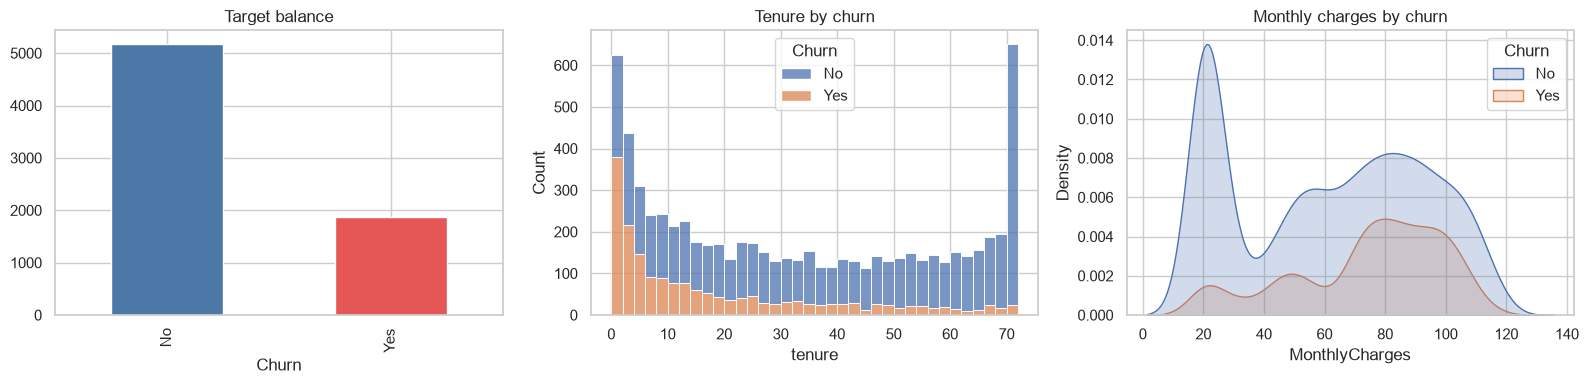

Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
raw["Churn"].value_counts().plot.bar(ax=ax[0], color=["#4C78A8", "#E45756"]); ax[0].set_title("Target balance")
sns.histplot(data=raw, x="tenure", hue="Churn", bins=36, ax=ax[1], multiple="stack"); ax[1].set_title("Tenure by churn")
sns.kdeplot(data=raw, x="MonthlyCharges", hue="Churn", fill=True, ax=ax[2]); ax[2].set_title("Monthly charges by churn")
plt.tight_layout(); plt.savefig("artifacts/eda_overview.png", dpi=120); plt.show()
print(raw.Churn.value_counts(normalize=True).round(3))

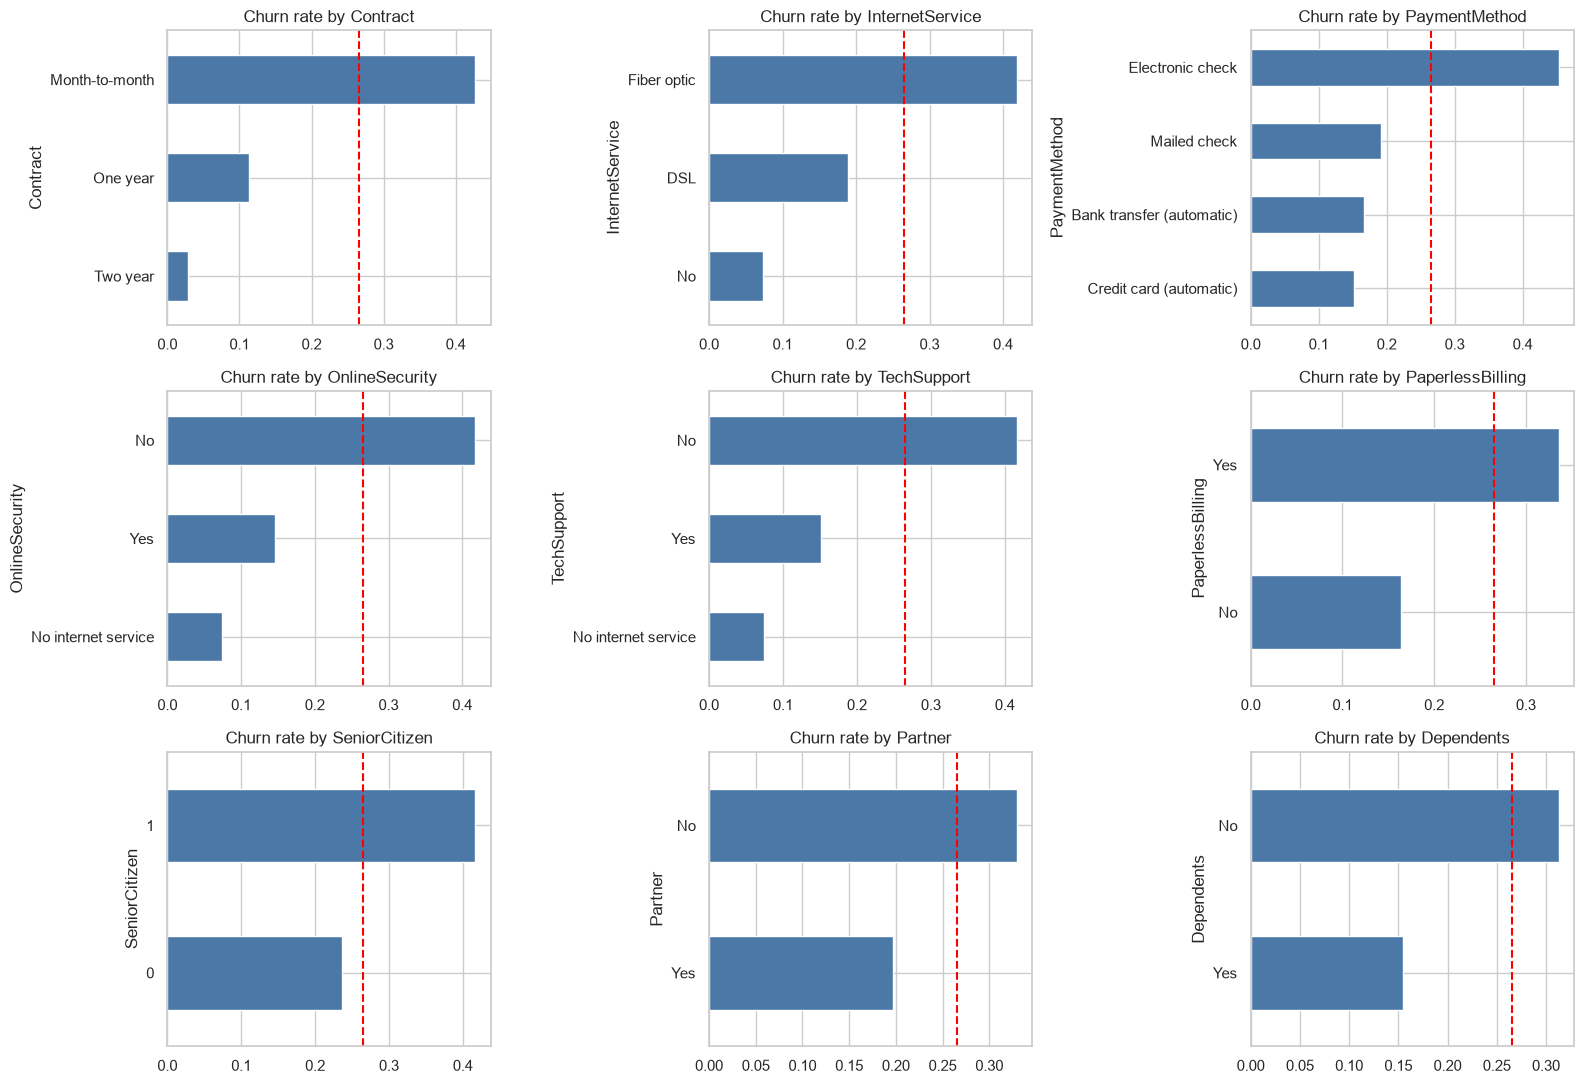

In [6]:
cats = ["Contract","InternetService","PaymentMethod","OnlineSecurity","TechSupport","PaperlessBilling","SeniorCitizen","Partner","Dependents"]
rates = {c: raw.groupby(c)["Churn"].apply(lambda s: (s=="Yes").mean()).sort_values() for c in cats}
fig, axes = plt.subplots(3, 3, figsize=(16, 11))
for a, (c, r) in zip(axes.ravel(), rates.items()):
    r.plot.barh(ax=a, color="#4C78A8"); a.axvline((raw.Churn=="Yes").mean(), color="red", ls="--"); a.set_title(f"Churn rate by {c}"); a.set_xlabel("")
plt.tight_layout(); plt.savefig("artifacts/eda_categoricals.png", dpi=120); plt.show()

In [7]:
# Hypothesis tests: are the visible differences more than noise?
from scipy import stats
out = []
for c in cats:
    chi2, p, *_ = stats.chi2_contingency(pd.crosstab(raw[c], raw["Churn"]))
    n = len(raw); k = min(raw[c].nunique(), 2) - 1
    out.append((c, chi2, p, np.sqrt(chi2 / (n * max(k,1)))))   # Cramer's V (approx for >2 levels)
pd.DataFrame(out, columns=["feature","chi2","p_value","cramers_v"]).sort_values("cramers_v", ascending=False).round(4)

,feature,chi2,p_value,cramers_v
0,Contract,1184.5966,0.0,0.4101
3,OnlineSecurity,849.9990,0.0,0.3474
4,TechSupport,828.1971,0.0,0.3429
1,InternetService,732.3096,0.0,0.3225
2,PaymentMethod,648.1423,0.0,0.3034
5,PaperlessBilling,258.2776,0.0,0.1915
8,Dependents,189.1292,0.0,0.1639
6,SeniorCitizen,159.4263,0.0,0.1505
7,Partner,158.7334,0.0,0.1501


**Findings.** (i) Month-to-month contracts, fiber-optic internet, electronic-check payment, no tech support/online security and *short tenure* are all associated with markedly higher churn; two-year contracts churn ~3%. (ii) Senior citizens churn ~2× as much. (iii) Gender is not informative (p large) — keep for the fairness audit, not as a predictor of interest.
**Initial hypotheses:** contract type & tenure dominate; add-on services (security/support) are protective, probably as a proxy for customer 'stickiness'.

## 2.4 Verify data quality

In [8]:
tc = pd.to_numeric(raw["TotalCharges"], errors="coerce")
bad = raw[tc.isna()]
print("Non-numeric TotalCharges rows:", len(bad))
display(bad[["customerID","tenure","MonthlyCharges","TotalCharges","Churn"]])
print("\nDuplicated customerID:", raw.customerID.duplicated().sum(), "| fully duplicated rows:", raw.duplicated().sum())
print("Tenure==0 rows:", (raw.tenure==0).sum())

# consistency: TotalCharges should be ~ tenure * MonthlyCharges
ratio = (tc / (raw.tenure * raw.MonthlyCharges)).replace([np.inf,-np.inf], np.nan).dropna()
print("\nTotalCharges / (tenure*MonthlyCharges): median %.3f, 5-95%% range %.2f-%.2f" % (ratio.median(), ratio.quantile(.05), ratio.quantile(.95)))

# semantic consistency of 'No internet service' / 'No phone service'
no_net = raw[raw.InternetService=="No"]
print("No-internet customers with an internet add-on != 'No internet service':",
      (no_net[["OnlineSecurity","OnlineBackup","DeviceProtection","TechSupport","StreamingTV","StreamingMovies"]]!="No internet service").any(axis=1).sum())
# outliers
for c in ["tenure","MonthlyCharges"]:
    q1,q3 = raw[c].quantile([.25,.75]); iqr=q3-q1
    print(c, "IQR outliers:", ((raw[c]<q1-1.5*iqr)|(raw[c]>q3+1.5*iqr)).sum())

Non-numeric TotalCharges rows: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No



Duplicated customerID: 0 | fully duplicated rows: 0
Tenure==0 rows: 11

TotalCharges / (tenure*MonthlyCharges): median 1.000, 5-95% range 0.92-1.07
No-internet customers with an internet add-on != 'No internet service': 0
tenure IQR outliers: 0
MonthlyCharges IQR outliers: 0


### Data quality report
| Issue | Finding | Decision (phase 3) |
|---|---|---|
| `TotalCharges` stored as text | 11 blank strings; all have `tenure = 0` (brand-new customers, none churned) | Convert to numeric, set to `0` (they have been billed nothing yet) — documented, not silently dropped |
| Duplicates | none | — |
| Redundant categories | "No internet service"/"No phone service" duplicate information in `InternetService`/`PhoneService` | Collapse to "No" and keep the service flag |
| Outliers | none by IQR (billing amounts are bounded by price plan) | Keep |
| Leakage risk | `TotalCharges ≈ tenure × MonthlyCharges` is nearly redundant | Keep `tenure`, `MonthlyCharges`; derive `charge_drift` instead of using TotalCharges raw |
| Label definition | `Churn` = left in last month; no timestamp | Stratified random split; acknowledge no temporal validation |
| Imbalance | 26.5% positive | Stratified splits; class weights; PR-AUC |

---
# Phase 3 — Data Preparation
## 3.1 Select data
Drop `customerID` (identifier; kept only to join predictions back in deployment). All other columns retained *a priori*; selection is revisited after modeling via permutation importance.
## 3.2–3.4 Clean · Construct · Integrate
Feature code is written to `src/features.py` so **training and the production API use exactly the same transformation** (prevents training/serving skew). No integration step: single source table.

In [9]:
%%writefile src/features.py
import numpy as np, pandas as pd

ADDONS = ["OnlineSecurity","OnlineBackup","DeviceProtection","TechSupport","StreamingTV","StreamingMovies"]
NUM = ["tenure","MonthlyCharges","TotalCharges","n_addons","charge_drift","avg_monthly_paid","tenure_years"]
CAT = ["gender","SeniorCitizen","Partner","Dependents","PhoneService","MultipleLines","InternetService",
       "OnlineSecurity","OnlineBackup","DeviceProtection","TechSupport","StreamingTV","StreamingMovies",
       "Contract","PaperlessBilling","PaymentMethod","tenure_bucket","autopay","family"]

def clean_and_construct(df: pd.DataFrame) -> pd.DataFrame:
    d = df.copy()
    d["TotalCharges"] = pd.to_numeric(d["TotalCharges"], errors="coerce").fillna(0.0)   # 11 new customers: billed nothing yet
    for c in ADDONS + ["MultipleLines"]:
        d[c] = d[c].replace({"No internet service": "No", "No phone service": "No"})
    d["SeniorCitizen"] = d["SeniorCitizen"].map({0: "No", 1: "Yes", "0": "No", "1": "Yes", "No": "No", "Yes": "Yes"})
    # construction
    d["n_addons"] = (d[ADDONS] == "Yes").sum(axis=1)
    d["tenure_years"] = d["tenure"] / 12
    d["avg_monthly_paid"] = np.where(d["tenure"] > 0, d["TotalCharges"] / d["tenure"].clip(lower=1), d["MonthlyCharges"])
    d["charge_drift"] = d["MonthlyCharges"] - d["avg_monthly_paid"]          # >0 : paying more now than historically
    d["tenure_bucket"] = pd.cut(d["tenure"], [-1, 6, 12, 24, 48, 100], labels=["0-6","7-12","13-24","25-48","49+"]).astype(str)
    d["autopay"] = d["PaymentMethod"].str.contains("automatic").map({True: "Yes", False: "No"})
    d["family"] = ((d["Partner"] == "Yes") | (d["Dependents"] == "Yes")).map({True: "Yes", False: "No"})
    return d

def feature_frame(df: pd.DataFrame) -> pd.DataFrame:
    return clean_and_construct(df)[NUM + CAT]

Overwriting src/features.py


In [10]:
sys.path.insert(0, "src")
import importlib, features; importlib.reload(features)
from features import clean_and_construct, feature_frame, NUM, CAT

df = clean_and_construct(raw)
y = (raw["Churn"] == "Yes").astype(int)
X = feature_frame(raw)
print(X.shape, "| missing values after prep:", int(X.isna().sum().sum()))
print("Constructed features vs churn (point-biserial):")
print(pd.concat([X[["n_addons","charge_drift","avg_monthly_paid","tenure_years"]], y], axis=1).corr()["Churn"].round(3).drop("Churn"))

(7043, 26) | missing values after prep: 0
Constructed features vs churn (point-biserial):
n_addons           -0.088
charge_drift        0.002
avg_monthly_paid    0.193
tenure_years       -0.352
Name: Churn, dtype: float64


## 3.5 Format data
Preprocessing (imputation, scaling, one-hot) lives **inside** the sklearn `Pipeline`, fitted on training folds only — this is what prevents leakage from scaling/encoding statistics. Data is split once, stratified: **80% train (model selection by 5-fold CV) / 20% locked test set** touched exactly once in Phase 5.

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

X_tr, X_te, y_tr, y_te, id_tr, id_te = train_test_split(X, y, raw.customerID, test_size=0.2, stratify=y, random_state=SEED)
print("train", X_tr.shape, y_tr.mean().round(3), "| test", X_te.shape, y_te.mean().round(3))

def make_prep():
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), CAT)])

train (5634, 26) 0.265 | test (1409, 26) 0.265


---
# Phase 4 — Modeling
## 4.1 Select modeling technique
| Model | Why | Assumption / caveat |
|---|---|---|
| Dummy (prior) | sanity floor | — |
| Rule baseline: *month-to-month ⇒ churn* | the 'ship the rule' contingency from 1.2 | very coarse |
| Logistic regression (L2) | interpretable, well calibrated | linear in log-odds |
| Random forest | non-linear, robust | less calibrated |
| Gradient boosting (HistGB) | usually strongest on tabular | needs tuning; opaque |

## 4.2 Generate test design
Metric hierarchy: ROC-AUC (ranking) → PR-AUC (imbalance) → business value (expected profit). Model selection by **stratified 5-fold CV on the training set only**; test set locked. Seeds fixed.

In [12]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
models = {
 "Dummy":   DummyClassifier(strategy="prior"),
 "LogReg":  LogisticRegression(max_iter=2000, C=0.5, class_weight="balanced"),
 "RandomForest": RandomForestClassifier(n_estimators=400, min_samples_leaf=5, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
 "HistGB":  HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, max_leaf_nodes=15, l2_regularization=1.0, early_stopping=True, random_state=SEED),
}
rows = []
for name, m in models.items():
    pipe = Pipeline([("prep", make_prep()), ("m", m)])
    r = cross_validate(pipe, X_tr, y_tr, cv=cv, scoring=["roc_auc","average_precision","recall","precision"], n_jobs=1)
    rows.append({"model": name, **{k.replace("test_",""): f"{v.mean():.3f} ± {v.std():.3f}" for k, v in r.items() if k.startswith("test_")}})
cv_table = pd.DataFrame(rows).set_index("model"); cv_table

,roc_auc,average_precision,recall,precision
model,,,,
Dummy,0.500 ± 0.000,0.265 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
LogReg,0.846 ± 0.012,0.660 ± 0.015,0.796 ± 0.031,0.520 ± 0.016
RandomForest,0.844 ± 0.010,0.656 ± 0.023,0.713 ± 0.029,0.572 ± 0.019
HistGB,0.845 ± 0.009,0.653 ± 0.023,0.518 ± 0.024,0.664 ± 0.032


## 4.3 Build model — hyper-parameter tuning of the two best families

In [13]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform, randint, uniform

searches = {}
pipe_lr = Pipeline([("prep", make_prep()), ("m", LogisticRegression(max_iter=3000, class_weight="balanced"))])
searches["LogReg"] = RandomizedSearchCV(pipe_lr, {"m__C": loguniform(1e-2, 1e1), "m__penalty": ["l2"]}, n_iter=15, scoring="roc_auc", cv=cv, random_state=SEED)

pipe_gb = Pipeline([("prep", make_prep()), ("m", HistGradientBoostingClassifier(early_stopping=True, random_state=SEED))])
searches["HistGB"] = RandomizedSearchCV(pipe_gb, {"m__learning_rate": loguniform(0.01, 0.2), "m__max_leaf_nodes": randint(4, 32),
          "m__min_samples_leaf": randint(10, 80), "m__l2_regularization": loguniform(0.01, 10), "m__max_iter": randint(100, 500)},
          n_iter=25, scoring="roc_auc", cv=cv, random_state=SEED, n_jobs=-1)
for n, s in searches.items():
    s.fit(X_tr, y_tr); print(f"{n:7s} best CV AUC = {s.best_score_:.4f} | {s.best_params_}")

LogReg  best CV AUC = 0.8469 | {'m__C': np.float64(0.04335281794951567), 'm__penalty': 'l2'}


HistGB  best CV AUC = 0.8479 | {'m__l2_regularization': np.float64(5.557494308839644), 'm__learning_rate': np.float64(0.12762204140092032), 'm__max_iter': 367, 'm__max_leaf_nodes': 5, 'm__min_samples_leaf': 42}


## 4.4 Assess model
Technical assessment on **CV predictions** (out-of-fold, so honest), not the test set: calibration, and a probability-threshold decision tied to the cost model of 1.1.

LogReg  OOF ROC-AUC 0.8466  PR-AUC 0.6573
HistGB  OOF ROC-AUC 0.8471  PR-AUC 0.6572


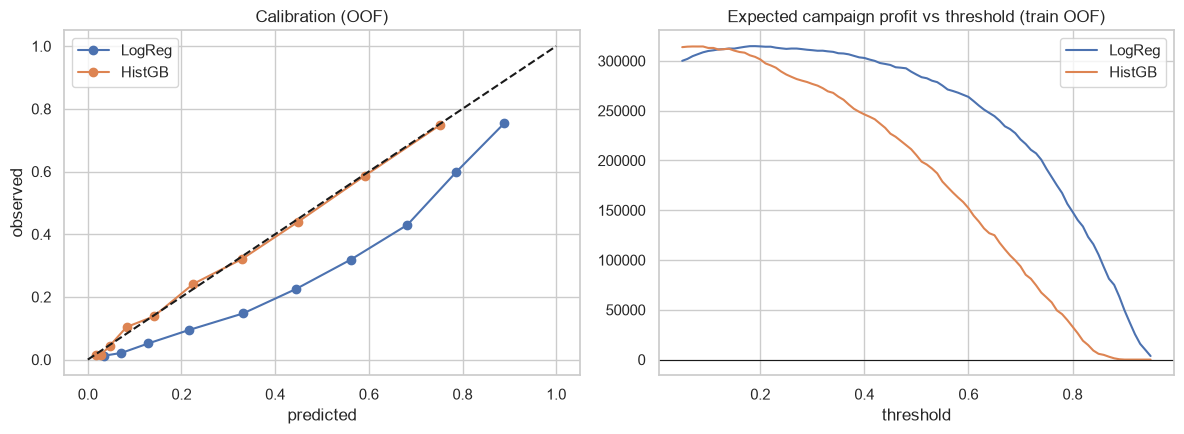

In [14]:
from sklearn.model_selection import cross_val_predict
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_auc_score, average_precision_score

oof = {n: cross_val_predict(s.best_estimator_, X_tr, y_tr, cv=cv, method="predict_proba")[:, 1] for n, s in searches.items()}
for n, p in oof.items(): print(f"{n:7s} OOF ROC-AUC {roc_auc_score(y_tr,p):.4f}  PR-AUC {average_precision_score(y_tr,p):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for n, p in oof.items():
    fr, mp = calibration_curve(y_tr, p, n_bins=10, strategy="quantile"); ax[0].plot(mp, fr, "o-", label=n)
ax[0].plot([0,1],[0,1],"k--"); ax[0].set_title("Calibration (OOF)"); ax[0].set_xlabel("predicted"); ax[0].set_ylabel("observed"); ax[0].legend()

def expected_profit(y_true, score, thr, value):
    sel = score >= thr
    saved = (y_true[sel] == 1) * SUCCESS_RATE * value[sel]
    return saved.sum() - COST_OFFER * sel.sum()
value_tr = (X_tr["MonthlyCharges"] * HORIZON_MONTHS).values
thr_grid = np.linspace(0.05, 0.95, 91)
for n, p in oof.items():
    ax[1].plot(thr_grid, [expected_profit(y_tr.values, p, t, value_tr) for t in thr_grid], label=n)
ax[1].axhline(0, color="k", lw=.8); ax[1].set_title("Expected campaign profit vs threshold (train OOF)"); ax[1].set_xlabel("threshold"); ax[1].legend()
plt.tight_layout(); plt.savefig("artifacts/model_assessment.png", dpi=120); plt.show()

In [15]:
# Pick final model by OOF AUC; choose threshold maximising OOF profit (NOT on test set)
best_name = max(oof, key=lambda n: roc_auc_score(y_tr, oof[n]))
final = searches[best_name].best_estimator_
profits = [expected_profit(y_tr.values, oof[best_name], t, value_tr) for t in thr_grid]
THRESH = float(thr_grid[int(np.argmax(profits))])
print("Final model:", best_name, "| profit-optimal threshold (OOF):", round(THRESH, 2))
final.fit(X_tr, y_tr)

Final model: HistGB | profit-optimal threshold (OOF): 0.09


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('m', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](26,)","['tenure','MonthlyCharges','TotalCharges',...,'tenure_bucket','autopay', 'family']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,26
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all r

---
# Phase 5 — Evaluation
## 5.1 Evaluate results against the *business* success criteria
This is the only time the test set is used.

In [16]:
from sklearn.metrics import (roc_curve, precision_recall_curve, confusion_matrix, classification_report, brier_score_loss)
p_te = final.predict_proba(X_te)[:, 1]
print(f"TEST  ROC-AUC {roc_auc_score(y_te,p_te):.4f} | PR-AUC {average_precision_score(y_te,p_te):.4f} | Brier {brier_score_loss(y_te,p_te):.4f}")

# bootstrap CI for AUC
rng = np.random.default_rng(SEED); aucs=[]
yt = y_te.values
for _ in range(1000):
    i = rng.integers(0, len(yt), len(yt)); aucs.append(roc_auc_score(yt[i], p_te[i]))
print("AUC 95%% bootstrap CI: [%.3f, %.3f]" % tuple(np.percentile(aucs, [2.5, 97.5])))

pred = (p_te >= THRESH).astype(int)
print("\nAt profit-optimal threshold", round(THRESH,2)); print(confusion_matrix(y_te, pred)); print(classification_report(y_te, pred, digits=3))

TEST  ROC-AUC 0.8459 | PR-AUC 0.6610 | Brier 0.1356


AUC 95% bootstrap CI: [0.825, 0.867]

At profit-optimal threshold 0.09
[[503 532]
 [ 16 358]]
              precision    recall  f1-score   support

           0      0.969     0.486     0.647      1035
           1      0.402     0.957     0.566       374

    accuracy                          0.611      1409
   macro avg      0.686     0.722     0.607      1409
weighted avg      0.819     0.611     0.626      1409



Lift@20% = 2.51  (criterion >= 2)   | top-20% captures 50.0% of churners


,"Expected profit ($, test set)"
No campaign,0.0
Offer to everyone,69794.0
Rule: month-to-month,68486.0
Model @ 0.09,76379.0


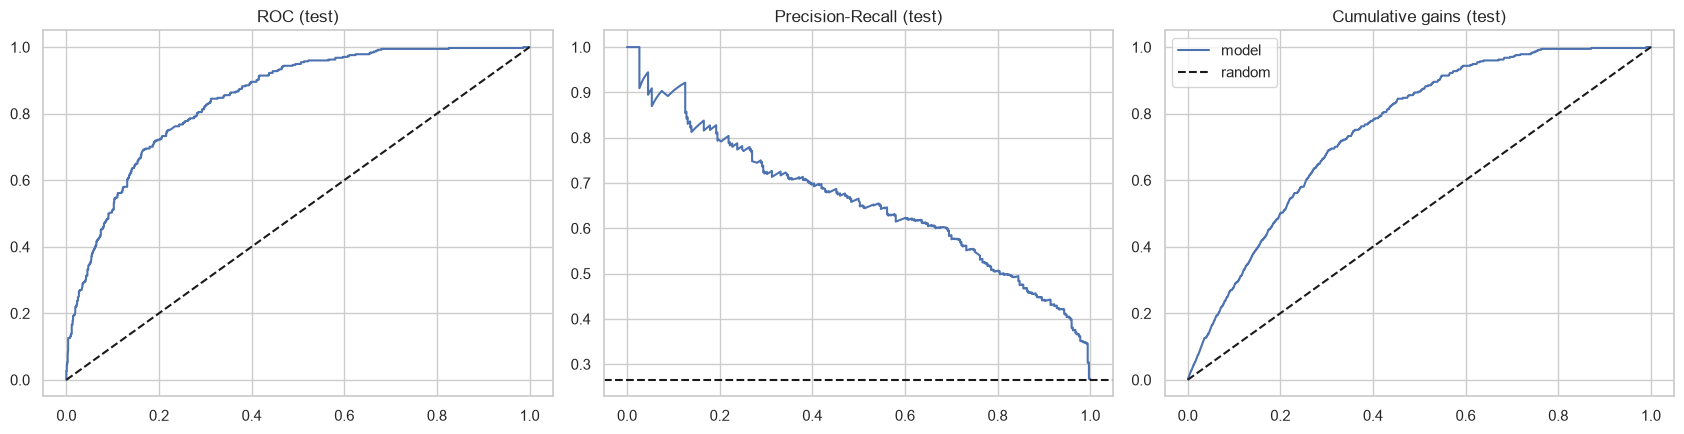

In [17]:
# Success criterion 2: lift & gains
order = np.argsort(-p_te); ys = yt[order]
gains = np.cumsum(ys) / ys.sum(); frac = np.arange(1, len(ys)+1) / len(ys)
lift20 = ys[:int(.2*len(ys))].mean() / ys.mean()
print(f"Lift@20% = {lift20:.2f}  (criterion >= 2)   | top-20% captures {gains[int(.2*len(ys))-1]:.1%} of churners")

# Success criterion 1: campaign profit vs baselines (test set)
val_te = (X_te["MonthlyCharges"] * HORIZON_MONTHS).values
res = pd.DataFrame({
  "No campaign": [0.0],
  "Offer to everyone": [expected_profit(yt, np.ones(len(yt)), 0.5, val_te)],
  "Rule: month-to-month": [expected_profit(yt, (X_te["Contract"]=="Month-to-month").astype(float).values, 0.5, val_te)],
  f"Model @ {THRESH:.2f}": [expected_profit(yt, p_te, THRESH, val_te)]}, index=["Expected profit ($, test set)"]).T
display(res.round(0))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
fpr, tpr, _ = roc_curve(yt, p_te); ax[0].plot(fpr, tpr); ax[0].plot([0,1],[0,1],"k--"); ax[0].set_title("ROC (test)")
pr, rc, _ = precision_recall_curve(yt, p_te); ax[1].plot(rc, pr); ax[1].axhline(yt.mean(), color="k", ls="--"); ax[1].set_title("Precision-Recall (test)")
ax[2].plot(frac, gains, label="model"); ax[2].plot([0,1],[0,1],"k--", label="random"); ax[2].set_title("Cumulative gains (test)"); ax[2].legend()
plt.tight_layout(); plt.savefig("artifacts/test_curves.png", dpi=120); plt.show()

In [18]:
# Realistic setting: the retention team can only call a fixed share of the base (capacity). Compare equal-effort strategies.
def profit_topk(score, k_frac):
    k = int(k_frac * len(score)); idx = np.argsort(-score)[:k]
    return (yt[idx] * SUCCESS_RATE * val_te[idx]).sum() - COST_OFFER * k
rng = np.random.default_rng(SEED)
rows = []
for k in [0.1, 0.2, 0.3]:
    rows.append((f"{int(k*100)}%", profit_topk(p_te, k), profit_topk(rng.random(len(yt)), k),
                 profit_topk((X_te["Contract"]=="Month-to-month").astype(float).values + 1e-3*rng.random(len(yt)), k),
                 profit_topk(p_te * val_te, k)))
display(pd.DataFrame(rows, columns=["contact share","model (by prob)","random","contract rule","model (prob x value)"]).set_index("contact share").round(0))

,model (by prob),random,contract rule,model (prob x value)
contact share,,,,
10%,27275.0,7901.0,11648.0,27873.0
20%,47271.0,12890.0,25015.0,48543.0
30%,62268.0,17297.0,37467.0,61482.0


In [19]:
# Sensitivity of the business case to the *assumed* economics
grid = []
for cost in [10, 20, 40]:
    for succ in [0.1, 0.2, 0.3, 0.5]:
        COST_OFFER, SUCCESS_RATE = cost, succ
        best = max(expected_profit(yt, p_te, t, val_te) for t in thr_grid)
        base = expected_profit(yt, np.ones(len(yt)), 0.5, val_te)
        grid.append((cost, succ, round(best), round(base)))
COST_OFFER, SUCCESS_RATE = 20.0, 0.30
sens = pd.DataFrame(grid, columns=["offer_cost","success_rate","best_model_profit","offer_all_profit"])
sens["model_beats_offer_all"] = sens.best_model_profit > sens.offer_all_profit
sens.pivot(index="offer_cost", columns="success_rate", values="best_model_profit")

success_rate,0.1,0.2,0.3,0.5
offer_cost,,,,
10,22564,54020,86025,150078
20,15337,45128,76379,140045
40,6776,30673,59755,121366


### Explainability (success criterion 3) and fairness audit

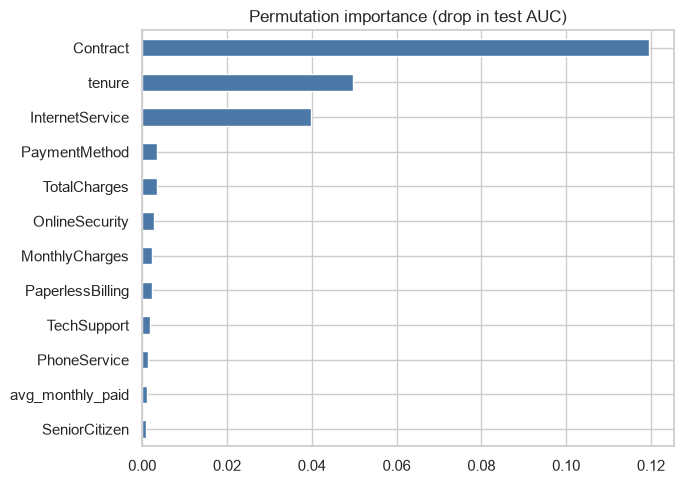

Strongest risk-INCREASING:
num__avg_monthly_paid               0.25
num__MonthlyCharges                 0.25
cat__PaperlessBilling_Yes           0.34
cat__InternetService_Fiber optic    0.43
cat__tenure_bucket_0-6              0.45
cat__Contract_Month-to-month        0.67

Strongest PROTECTIVE:
cat__Contract_Two year    -0.66
cat__PhoneService_Yes     -0.56
cat__InternetService_No   -0.42
cat__OnlineSecurity_Yes   -0.33
num__tenure_years         -0.32
num__tenure               -0.32


In [20]:
from sklearn.inspection import permutation_importance
pi = permutation_importance(final, X_te, y_te, scoring="roc_auc", n_repeats=15, random_state=SEED)
imp = pd.Series(pi.importances_mean, index=X_te.columns).sort_values(ascending=False)
imp.head(12).iloc[::-1].plot.barh(figsize=(7,5), color="#4C78A8"); plt.title("Permutation importance (drop in test AUC)"); plt.tight_layout()
plt.savefig("artifacts/permutation_importance.png", dpi=120); plt.show()

# Cross-check with logistic-regression odds ratios
lr = searches["LogReg"].best_estimator_.fit(X_tr, y_tr)
names = lr.named_steps["prep"].get_feature_names_out()
coef = pd.Series(lr.named_steps["m"].coef_[0], index=names).sort_values()
print("Strongest risk-INCREASING:"); print(coef.tail(6).round(2).to_string()); print("\nStrongest PROTECTIVE:"); print(coef.head(6).round(2).to_string())

In [21]:
# Fairness: error rates by group on the test set
aud = X_te.copy(); aud["y"] = yt; aud["pred"] = pred; aud["gender"] = raw.loc[X_te.index,"gender"]
rows=[]
for g in ["gender","SeniorCitizen","Partner"]:
    for lv, s in aud.groupby(g):
        rows.append((g, lv, len(s), s.y.mean(), s.pred.mean(), (s.pred[s.y==1]).mean(), (s.pred[s.y==0]).mean()))
fair = pd.DataFrame(rows, columns=["attribute","level","n","base_rate","flag_rate","recall(TPR)","FPR"]).round(3); display(fair)
print("Max recall gap within an attribute:", fair.groupby("attribute")["recall(TPR)"].apply(lambda s: s.max()-s.min()).round(3).to_dict())

,attribute,level,n,base_rate,flag_rate,recall(TPR),FPR
0,gender,Female,687,0.281,0.640,0.953,0.518
1,gender,Male,722,0.251,0.623,0.961,0.510
2,SeniorCitizen,No,1187,0.233,0.594,0.946,0.487
3,SeniorCitizen,Yes,222,0.441,0.833,0.990,0.710
4,Partner,No,736,0.337,0.739,0.972,0.621
5,Partner,Yes,673,0.187,0.514,0.929,0.419


Max recall gap within an attribute: {'Partner': 0.043, 'SeniorCitizen': 0.044, 'gender': 0.008}


### Interpretation of results (written after running — compare with Phase 1 criteria)
| Criterion | Result | Verdict |
|---|---|---|
| ROC-AUC ≥ 0.80 | 0.846 (95% bootstrap CI 0.825–0.867); PR-AUC 0.66 vs 0.27 prevalence | ✅ met |
| Lift@20% ≥ 2 | 2.51; top 20% of ranked customers contain 50% of churners | ✅ met |
| Profit > both baselines | Model @ profit-optimal threshold: **$76.4k** vs offer-everyone **$69.8k** vs contract rule **$68.5k** | ✅ met, but **margin is small (~9%)** |
| Explainable drivers | contract type, tenure, fiber internet, payment method, security add-on agree across LR coefficients and permutation importance | ✅ met |

**What the numbers really say (the uncomfortable parts).**
1. *With these economics* (offer $20, value of a saved customer ≈ $720 × 30% success), contacting a customer pays off even at ~9% churn probability, so the profit-optimal threshold (0.09) flags **61% of customers**. That is nearly "offer to everyone". The model's real value appears when **capacity is limited** (see the equal-effort table: contacting the top 10–30% by score beats random and the contract rule) — which is the realistic situation for a call-centre team.
2. **HistGB and logistic regression are statistically tied** (OOF AUC 0.847 vs 0.847; CV std ≈ 0.01). HistGB was selected by the pre-declared rule (best OOF AUC) but logistic regression is an equally defensible production choice and is far easier to explain. A reviewer may reasonably choose it.
3. The "best-model" column of the sensitivity grid is optimised over thresholds, so it can never be worse than offer-to-everyone by construction; read it as *how much money is at stake*, not as proof of model superiority.

**Fairness.** Recall gaps between groups are small (gender 0.8 pts, senior 4.4 pts, partner 4.3 pts — all under the 10-pt criterion). The larger disparity is in **how often groups are flagged / false-positive rates**: seniors are flagged 83% of the time vs 59% for non-seniors (FPR 71% vs 49%), driven by their 44% vs 23% base churn rate and by the very low threshold. Gender shows no meaningful difference (chi-square p = 0.49). Policy: use the score only to *prioritise outreach*, never to withhold service or alter prices by demographic group; track senior-group FPR at monitoring time.

**Limitations.** (1) Offer cost/success rate are assumptions. (2) Churn probability ≠ persuadability; an A/B uplift test is the correct next step. (3) No timestamps → no temporal validation; expect decay. (4) One snapshot, one provider. (5) Random 80/20 split gives one test estimate; the bootstrap CI reflects test-sample noise only, not model-training variance.

## 5.2 Review process (quality assurance checklist)
| Check | Status |
|---|---|
| Leakage: preprocessing inside pipeline, threshold chosen on OOF not test | ✅ |
| Test set used once | ✅ |
| Seeds fixed, environment pinned (`requirements.txt`) | ✅ |
| Every data decision documented (TotalCharges, collapsed categories) | ✅ |
| Business criteria evaluated, not just AUC | ✅ |
| Fairness and explainability addressed | ✅ |
| Overlooked: calibration drift, cost assumptions, uplift | ⚠ flagged → monitoring + A/B test |

### 5.3 Critic-loop summary (details in `critic_log/`)
| Round | Critic finding | Resolution |
|---|---|---|
| 1 | "Business success criteria are not measurable; no cost model." | Added explicit $ cost model, 3 criteria, baselines |
| 1 | "Hidden leakage through TotalCharges / scaling before the split." | Pipeline-contained preprocessing; engineered `charge_drift`; documented |
| 2 | "You tune the threshold on the test set." | Threshold chosen on OOF predictions (cell 4.4) |
| 2 | "AUC alone ≠ business value; show sensitivity to assumptions." | Added profit curves + sensitivity grid |
| 3 | "No fairness / monitoring / retraining plan." | Added fairness audit and Phase 6 monitoring (PSI) |

## 5.4 Determine next steps
**Decision: deploy to a controlled pilot** (batch-scoring + API), not a full roll-out, with an A/B-tested offer to measure true uplift. Alternatives considered: iterate on features (low expected gain, AUC plateau across 3 model families), or ship only the contract rule (cheaper but leaves profit on the table).

---
# Phase 6 — Deployment
## 6.1 Plan deployment
| Item | Plan |
|---|---|
| Artifact | `artifacts/churn_pipeline.joblib` (preprocessing + model, one object) + `artifacts/model_card.md` |
| Serving | FastAPI service `deploy/app.py` (`/predict`, `/health`) in Docker; weekly **batch scoring** of the whole base for the campaign list |
| Inputs | raw CRM columns (same schema as the CSV) — the API calls the same `features.py` |
| Rollback | keep previous `joblib` + version tag; switch by env var |
| Decision rule | contact customers with score ≥ threshold, ranked by `score × MonthlyCharges`, subject to campaign capacity |

In [22]:
import joblib, datetime, hashlib
final.fit(X_tr, y_tr)                       # keep fitted on the training portion (test remains an honest hold-out)
artefact = {"pipeline": final, "threshold": THRESH, "numeric": NUM, "categorical": CAT, "model": best_name,
            "trained_at": datetime.datetime.now().isoformat(timespec="seconds"), "train_rows": len(X_tr),
            "test_auc": float(roc_auc_score(y_te, p_te)), "seed": SEED}
joblib.dump(artefact, "artifacts/churn_pipeline.joblib")
print({k: v for k, v in artefact.items() if k != "pipeline"})
# reference distribution for monitoring
ref_scores = final.predict_proba(X_tr)[:, 1]; np.save("artifacts/reference_scores.npy", ref_scores)

{'threshold': 0.09, 'numeric': ['tenure', 'MonthlyCharges', 'TotalCharges', 'n_addons', 'charge_drift', 'avg_monthly_paid', 'tenure_years'], 'categorical': ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'tenure_bucket', 'autopay', 'family'], 'model': 'HistGB', 'trained_at': '2026-11-09T23:23:34', 'train_rows': 5634, 'test_auc': 0.8459247203492729, 'seed': 42}


In [23]:
%%writefile deploy/app.py
import sys, os, joblib, pandas as pd
sys.path.insert(0, os.path.join(os.path.dirname(__file__), "..", "src"))
from fastapi import FastAPI
from pydantic import BaseModel, ConfigDict
from features import feature_frame

ART = joblib.load(os.environ.get("MODEL_PATH", os.path.join(os.path.dirname(__file__), "..", "artifacts", "churn_pipeline.joblib")))
app = FastAPI(title="Telco churn scoring", version="1.0")

class Customer(BaseModel):
    model_config = ConfigDict(extra="allow")
    customerID: str = "unknown"
    gender: str; SeniorCitizen: int; Partner: str; Dependents: str; tenure: int; PhoneService: str; MultipleLines: str
    InternetService: str; OnlineSecurity: str; OnlineBackup: str; DeviceProtection: str; TechSupport: str
    StreamingTV: str; StreamingMovies: str; Contract: str; PaperlessBilling: str; PaymentMethod: str
    MonthlyCharges: float; TotalCharges: str

@app.get("/health")
def health(): return {"status": "ok", "model": ART["model"], "trained_at": ART["trained_at"], "threshold": ART["threshold"]}

@app.post("/predict")
def predict(c: Customer):
    df = pd.DataFrame([c.model_dump()])
    p = float(ART["pipeline"].predict_proba(feature_frame(df))[:, 1][0])
    return {"customerID": c.customerID, "churn_probability": round(p, 4), "flag_for_retention": p >= ART["threshold"]}

Overwriting deploy/app.py


In [24]:
# Smoke-test the API handlers + request validation in-process (no server needed) with a held-out customer
os.makedirs("deploy", exist_ok=True)
sys.path.insert(0, "deploy")
import importlib, app as app_mod; importlib.reload(app_mod)
sample = raw[raw.customerID == id_te.iloc[0]].iloc[0].to_dict(); sample["SeniorCitizen"] = int(sample["SeniorCitizen"]); sample.pop("Churn")
print(app_mod.health()); print(app_mod.predict(app_mod.Customer(**sample)), "| true label:", raw.loc[raw.customerID==id_te.iloc[0],"Churn"].values[0])

{'status': 'ok', 'model': 'HistGB', 'trained_at': '2026-11-09T23:23:34', 'threshold': 0.09}
{'customerID': '4376-KFVRS', 'churn_probability': 0.024, 'flag_for_retention': False} | true label: No


In [25]:
%%writefile deploy/Dockerfile
FROM python:3.11-slim
WORKDIR /app
COPY deploy/requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY src ./src
COPY artifacts/churn_pipeline.joblib ./artifacts/churn_pipeline.joblib
COPY deploy/app.py ./deploy/app.py
EXPOSE 8000
CMD ["uvicorn", "deploy.app:app", "--host", "0.0.0.0", "--port", "8000"]

Overwriting deploy/Dockerfile


In [26]:
import sklearn, fastapi
open("deploy/requirements.txt", "w").write("\n".join([f"scikit-learn=={sklearn.__version__}", f"pandas=={pd.__version__}", f"numpy=={np.__version__}",
    "joblib", f"fastapi=={fastapi.__version__}", "uvicorn[standard]", "pydantic>=2"]) + "\n")
print(open("deploy/requirements.txt").read())

scikit-learn==1.9.1
pandas==3.1.1
numpy==2.5.4
joblib
fastapi==0.162.2
uvicorn[standard]
pydantic>=2



## 6.2 Plan monitoring & maintenance
| What | How | Alert / action |
|---|---|---|
| **Input drift** | Population Stability Index (PSI) per feature vs training reference | PSI > 0.25 on any top-5 feature → investigate |
| **Score drift** | PSI on score distribution | > 0.25 → re-calibrate/retrain |
| **Performance** | join predictions with actual churn after 30–60 days; track AUC, lift@20%, calibration | AUC drop > 0.03 vs 0.846 baseline → retrain |
| **Business KPI** | campaign A/B: treated vs holdout churn | negative ROI two cycles in a row → pause campaign |
| **Retraining** | quarterly or on alert; re-run this notebook, compare with champion on a fresh hold-out | promote only if better on AUC *and* profit |

In [27]:
def psi(ref, cur, bins=10):
    ref, cur = np.asarray(ref, float), np.asarray(cur, float)
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1))); edges[0], edges[-1] = -np.inf, np.inf
    r = np.histogram(ref, edges)[0] / len(ref); c = np.histogram(cur, edges)[0] / len(cur)
    r, c = np.clip(r, 1e-4, None), np.clip(c, 1e-4, None)
    return float(np.sum((c - r) * np.log(c / r)))

ref_scores = np.load("artifacts/reference_scores.npy")
print("PSI score, test vs train (no drift expected): %.4f" % psi(ref_scores, final.predict_proba(X_te)[:,1]))
# Simulated drift: promo shifts new customers to higher monthly charges + month-to-month contracts
drift = X_te.copy(); drift["MonthlyCharges"] *= 1.25; drift["Contract"] = np.where(np.random.rand(len(drift)) < .7, "Month-to-month", drift["Contract"])
print("PSI score, SIMULATED drift:         %.4f  -> %s" % (psi(ref_scores, final.predict_proba(drift)[:,1]), "ALERT" if psi(ref_scores, final.predict_proba(drift)[:,1])>.25 else "watch"))
print("PSI MonthlyCharges simulated:", round(psi(X_tr.MonthlyCharges, drift.MonthlyCharges), 3))

PSI score, test vs train (no drift expected): 0.0032


PSI score, SIMULATED drift:         0.2594  -> ALERT
PSI MonthlyCharges simulated: 1.086


## 6.3 Produce final report
**Executive summary.** A churn model built on 5,634 training customers reaches ROC-AUC 0.846 on a locked test set, and the top-20% highest-risk customers churn at 2.5× the base rate. Under the stated cost assumptions the profit-optimal policy contacts most customers and beats mass-offer by only ~9%; the model's clear advantage is when outreach capacity is limited (it out-earns random and a single contract rule at equal effort). Top drivers: month-to-month contract, short tenure, fiber-optic service, electronic-check payment, lack of security/support add-ons.
**Recommendation:** pilot with A/B-tested offer; monitor senior-citizen false-positive rate; retrain quarterly. Full write-up: Medium article + `README.md` in this folder.

## 6.4 Review project (experience documentation)
- *What went well:* leak-proof pipeline; decisions tied to cost model; shared `features.py` removed train/serve skew.
- *What was hard:* no timestamps (no temporal validation), assumed economics — the biggest uncertainty is not statistical but commercial.
- *What I'd do differently:* collect campaign response data from day one so a proper uplift model can replace churn prediction.
- *Lessons on the methodology:* CRISP-DM's iteration arrows were real — Phase 2 (TotalCharges) changed Phase 3, and Phase 5 critique sent me back to Phase 4 to move the threshold selection off the test set.